# 21. 권역 전체 대비 광역버스 수요의 상대적 유지 격자 순위

## 연구 방향

**GTX-A에서 권역 전체보다 수요가 상대적으로 덜 감소한 격자가 더 높은 점수를 받도록 학습하고, 새로운 역 권역의 개통 전 특성으로 격자 순위를 도출한다.** 증가 격자도 권역 대비 변화율이 높으면 여기에 포함된다.

현재 단계는 기존 순위모형을 활용한 탐색이며 GTX-C 최종 검증이 아니다. 이번에는 기존 상위20% 27개가 실제로 권역 전체보다 **얼마나 덜 감소했는지(%p)**를 사후 확인한다. 이 크기를 학습 정답으로 바꾸지 않는다.

- 방법: 기존 `12-8` L2 규제 쌍대비교 로지스틱. 같은 역의 상대적 유지 격자와 그렇지 않은 격자의 특성 차이로 양방향 비교쌍을 구성한다.
- 입력4개 고정: 개통 전 권역 내 수요 비중(%), log(1+개통 전 승차인원), **보행시간 원 단위(분)**, GTX 경쟁 목적지 비율(%). 뒤의 OLS/Ridge 실험에서 쓴 로그 보행으로 바꾸지 않는다.
- 외부 역 제외 및 학습역 내부 C 선택 절차를 그대로 재현한다. 저장된 고정 OOF 파일을 불러온 것은 아니며, 기존 코드 재실행에 의한 재현이다. 새 독립 검증이 아니다.
- Y=격자 변화율−소속 역 권역 총량 변화율. 기초승차량이 양수인 현재126개에서 Y>0은 기존 비중 확대 라벨과 동일하다.
- Y와 사후 승차량은 이번 점수·순위·상위격자 선택에 사용하지 않는다. 점수는 확률도 예상 변화율도 아니다.
- 전체126개 모두 권역 내 순위를 갖는다. 상위20%는 기존 평가 범위를 그대로 진단하는 것이며 ‘유지 확정’ 기준이 아니다.
- 같은 역권역의 상위27개 셀 ID와 실제22개 적중이 이전 결과와 동일한지 검사한다. 기존 모형·OLS·다른 노트북을 수정하지 않는다. CSV/모델/그림 파일 자동 저장 없음.

In [1]:
# 프로젝트 루트(UROP) 자동 탐색 — 절대경로 없이 어느 컴퓨터에서도 동작
import sys
from pathlib import Path
UROP_ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'config.py').is_file() and (p / 'code').is_dir())
for _d in [UROP_ROOT, *sorted(d for d in (UROP_ROOT / 'code').rglob('*') if d.is_dir() and d.name != '__pycache__')]:
    if str(_d) not in sys.path:
        sys.path.append(str(_d))

from pathlib import Path
import importlib.util
import pandas as pd, numpy as np, matplotlib.pyplot as plt
from matplotlib import font_manager
from IPython.display import display
paths=[*sorted(d for d in (UROP_ROOT / 'code').rglob('*') if d.is_dir()), Path.cwd(),Path.cwd()/'analysis',Path.cwd()/'gtx_a_bus_analysis'/'analysis',Path.cwd()/'github_2026-UROP'/'gtx_a_bus_analysis'/'analysis']
ANALYSIS=next((p for p in paths if (p/'21_쌍대순위_상대적유지_실제차이검증.py').exists()),None)
if ANALYSIS is None:raise FileNotFoundError('프로젝트 또는 analysis 폴더에서 실행하세요.')
spec=importlib.util.spec_from_file_location('relative_rank_check',next((UROP_ROOT / 'code').rglob('21_쌍대순위_상대적유지_실제차이검증.py')))
experiment=importlib.util.module_from_spec(spec);spec.loader.exec_module(experiment)
fonts={f.name for f in font_manager.fontManager.ttflist}
font=next((f for f in ['AppleGothic','Apple SD Gothic Neo','NanumGothic','Malgun Gothic','Noto Sans CJK KR'] if f in fonts),None)
if font:plt.rcParams['font.family']=font
plt.rcParams.update({'axes.unicode_minus':False,'figure.dpi':110,'font.size':11})
pd.set_option('display.max_columns',25)
oof,top,folds,summary,diagnostic=experiment.evaluate()
print('원래126개의 역별 OOF 순위 재현. 상위27개 셀 ID와 22개 적중 일치 검사 통과.')
display(folds.round(4))
print('역별 AUC 평균:',round(folds['외부AUC'].mean(),4))

원래126개의 역별 OOF 순위 재현. 상위27개 셀 ID와 22개 적중 일치 검사 통과.
역별 AUC 평균: 0.7311


,검증역,n,선택C,내부AUC,외부AUC,상위수,Precision20,Lift20
0,대곡,37,31.6228,0.7481,0.6842,8,0.7500,1.5417
1,운정중앙,63,0.1000,0.6820,0.7769,13,0.8462,1.5679
2,킨텍스,26,0.3162,0.7262,0.7321,6,0.8333,1.5476


## 1. 상위격자의 실제 상대적 변화율 차이

Y=+20%p는 소속 권역 전체보다 격자 변화율이20%p 높다는 뜻이다. 미래 변화율 예측값이 아니다. 비교집단(나머지99개)도 동일한 외부검증 격자에서 구분한다. 이 사후 분석으로 상위비율을 변경하지 않는다.

평균은 극단값의 영향을 받으므로 중앙값·사분위·범위를 함께 본다. 승차량 가중평균은 큰 수요 거점에 가중치를 주는 별도의 요약이므로 격자별 동일 가중 중앙값과 추정 대상이 다르다.

In [2]:
display(summary.round(3))
columns=['nearest_station','셀 ID','권역내순위','board_2024_all','board_2025_all','R_s','R_i','Y']
view=top[columns].rename(columns={'nearest_station':'권역','board_2024_all':'개통전승차','board_2025_all':'개통후승차','R_s':'권역변화율(%)','R_i':'격자변화율(%)','Y':'상대적차이(%p)'})
with pd.option_context('display.max_rows',40):display(view.round(3))

,권역,구분,n,권역보다덜감소수,비율,Y중앙값(%p),Y평균(%p),Y25분위,Y75분위,Y최소,Y최대,Y승차량가중평균(%p),0<Y≤2수,Y≥20수,Y≥30수,기초5미만수,기초10미만수,기초20미만수
0,전체,상위20%,27,22,0.815,15.796,44.937,1.914,61.251,-21.179,361.251,4.462,2,13,13,11,17,22
1,전체,나머지,99,44,0.444,-1.249,1.087,-8.297,8.093,-32.499,70.559,-0.827,8,8,7,3,7,19
2,대곡,상위20%,8,6,0.750,13.524,63.598,5.257,61.251,-5.416,361.251,9.969,0,3,3,6,6,7
3,대곡,나머지,29,12,0.414,-1.540,-2.463,-12.595,7.821,-32.499,36.251,-3.113,3,1,1,1,3,8
4,운정중앙,상위20%,13,11,0.846,37.226,47.069,3.893,70.559,-12.774,170.559,39.164,0,8,8,5,10,13
5,운정중앙,나머지,50,23,0.460,-1.187,3.787,-6.411,10.281,-23.191,70.559,-0.526,2,6,5,2,4,11
6,킨텍스,상위20%,6,5,0.833,1.914,15.438,0.403,23.599,-21.179,79.254,1.387,2,2,2,0,1,2
7,킨텍스,나머지,20,9,0.450,-1.952,-0.514,-7.977,4.947,-12.057,33.289,-0.433,3,1,1,0,0,0


,권역,셀 ID,권역내순위,개통전승차,개통후승차,권역변화율(%),격자변화율(%),상대적차이(%p)
0,대곡,14004,1,1.0,4.0,-61.251,300.000,361.251
1,대곡,1518,2,3.0,1.0,-61.251,-66.667,-5.416
2,대곡,9285,3,3.0,1.0,-61.251,-66.667,-5.416
3,대곡,7368,4,3.0,3.0,-61.251,0.000,61.251
4,대곡,1962,5,4.0,4.0,-61.251,0.000,61.251
5,대곡,7608,6,11.0,6.0,-61.251,-45.455,15.796
6,대곡,8805,7,4.0,2.0,-61.251,-50.000,11.251
7,대곡,12461,8,595.0,283.0,-61.251,-52.437,8.814
37,운정중앙,7262,1,1.0,2.0,-70.559,100.000,170.559
38,운정중앙,4768,2,1.0,1.0,-70.559,0.000,70.559


## 2. 기존 상위 순서와 실제 Y

가로축은 권역 내 예측 순위다. 세로축은 사후에 관찰한 실제 Y다. 양수면 권역보다 상대적으로 잘 유지됐고, 음수면 권역보다 더 감소했다. **양수들 사이에서도 큰 Y 순서대로 정렬하도록 학습한 것은 아니다.**

각 막대 위 숫자는 실제 Y다. 소규모 격자의 큰 Y를 반드시 앞의 승차량 표와 함께 확인한다.

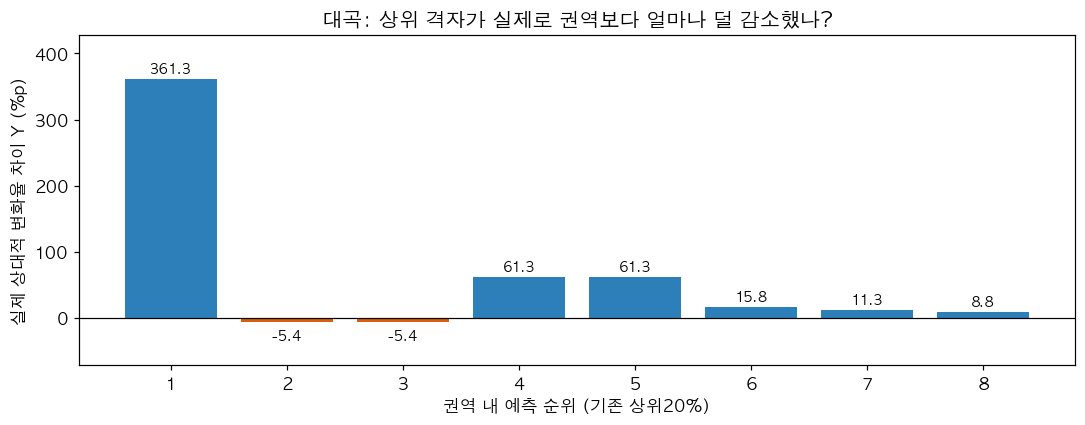

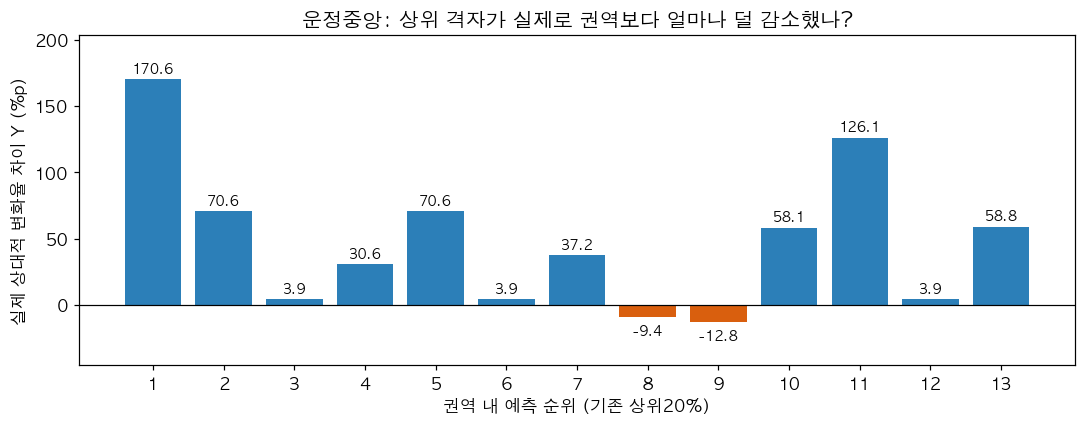

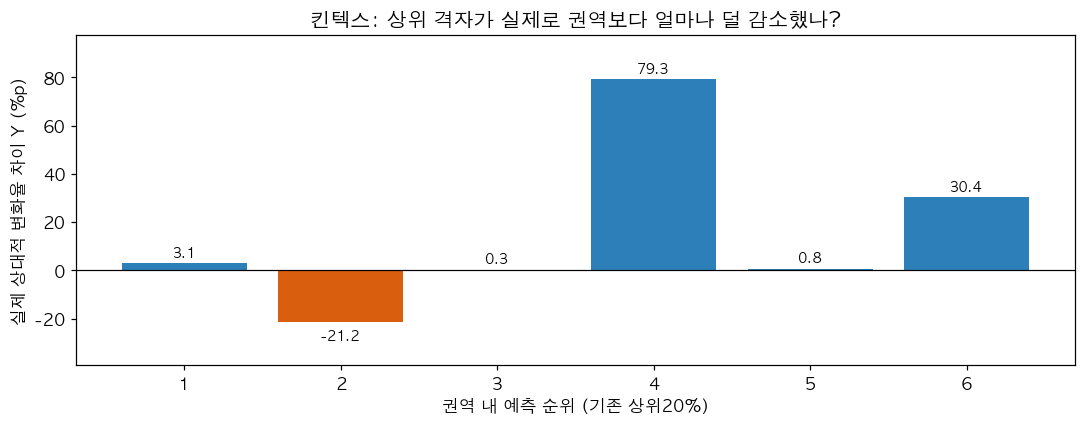

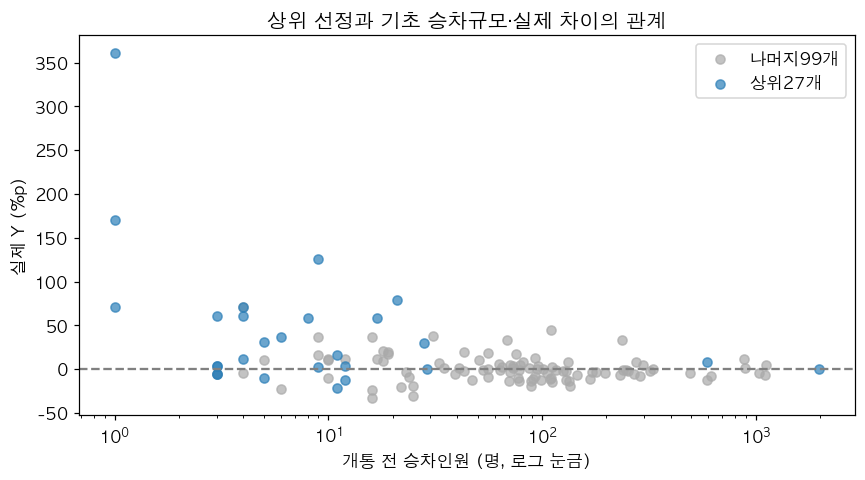

In [3]:
for station,g in top.groupby('nearest_station',sort=False):
 g=g.sort_values('권역내순위')
 fig,ax=plt.subplots(figsize=(10,4))
 ax.bar(g['권역내순위'].astype(str),g.Y,color=np.where(g.Y>0,'#2C7FB8','#D95F0E'))
 for x,y in enumerate(g.Y):ax.annotate(f'{y:.1f}',(x,y),xytext=(0,4 if y>=0 else -12),textcoords='offset points',ha='center',fontsize=9)
 ax.axhline(0,color='black',lw=.8);ax.margins(y=.18)
 ax.set(xlabel='권역 내 예측 순위 (기존 상위20%)',ylabel='실제 상대적 변화율 차이 Y (%p)',title=f'{station}: 상위 격자가 실제로 권역보다 얼마나 덜 감소했나?')
 plt.tight_layout();plt.show()
fig,ax=plt.subplots(figsize=(8,4.5))
for selected,label,col in [(False,'나머지99개','#AAAAAA'),(True,'상위27개','#2C7FB8')]:
 g=oof[oof['상위20%']==selected]
 ax.scatter(g.board_2024_all,g.Y,label=label,color=col,alpha=.7)
ax.set_xscale('log');ax.axhline(0,color='gray',ls='--')
ax.set(xlabel='개통 전 승차인원 (명, 로그 눈금)',ylabel='실제 Y (%p)',title='상위 선정과 기초 승차규모·실제 차이의 관계')
ax.legend();plt.tight_layout();plt.show()

## 3. 작은 승차량의 영향 분리

아래는 **기존에 선정된27개를 그대로 둔 채** 기초 규모별 내용을 확인하는 표다. 격자를 제외해 재학습하거나, 비선정 격자로 상위 순위를 다시 채운 것이 아니다. 이 기준을 최종 적용 문턱값으로 선택하지 않는다. 특히20명 이상은5개뿐이라 안정성을 입증하는 표가 아니다.

In [4]:
display(diagnostic.round(3))
print('정답 Y는 평가에서만 사용. 실제 C에 적용하려면 개통 전 입력의 공통 정의와 분포를 먼저 확인해야 한다.')

정답 Y는 평가에서만 사용. 실제 C에 적용하려면 개통 전 입력의 공통 정의와 분포를 먼저 확인해야 한다.


,기초기준,n,권역보다덜감소수,비율,Y중앙값(%p),Y평균(%p),Y25분위,Y75분위,Y최소,Y최대,Y승차량가중평균(%p),0<Y≤2수,Y≥20수,Y≥30수,기초5미만수,기초10미만수,기초20미만수
0,0,27,22,0.815,15.796,44.937,1.914,61.251,-21.179,361.251,4.462,2,13,13,11,17,22
1,5,16,13,0.812,12.305,25.604,0.644,42.434,-21.179,126.115,4.023,2,7,7,0,6,11
2,10,10,8,0.800,6.353,16.409,0.403,26.782,-21.179,79.254,3.368,2,3,3,0,0,5
3,20,5,5,1.000,8.814,23.912,0.765,30.444,0.283,79.254,3.134,2,2,2,0,0,0


## 4. 이번 확인 결과와 채택할 설명

- 기존 상위27개 중22개(81.5%)가 실제로 권역보다 높은 변화율을 보였다. 상위27개의 실제 Y 중앙값은 **+15.80%p**, 나머지99개는 **−1.25%p**였다.
- 상위27개 중 **13개는 Y≥20%p**였고 이13개 모두30%p 이상이었다. **0<Y≤2%p는2개**다. 따라서 상위 결과가 모두1~2%p 수준에 그친 것은 아니다.
- 역별 상위 Y 중앙값은 대곡+13.52/운정중앙+37.23/킨텍스+1.91%p. 방향 판별 적중률이 비슷해도 실제 차이의 크기까지 역마다 같은 것은 아니다.
- 상위27개의 Y 평균+44.94%p는 작은 분모의 극단값 영향을 받는다. 1→4명 대곡 격자는 Y+361.25%p다. 상위27개 중11개는 기초5명 미만,22개는20명 미만이다.
- 기존 상위27개 중 기초10명 이상10개만 보면 Y 중앙값+6.35%p,8개가Y>0이다. 이는 부분집합 설명이며 ‘10명 기준 재학습 성능’이 아니다.
- 격자별 동일 가중 중앙값과 별도로, 상위27개의 개통 전 승차량 가중 Y 평균은+4.46%p(킨텍스+1.39%p)였다. 수요규모 관점에서는 차이가 작을 수 있다는 것도 함께 제시한다.

**현재 연구 방향:** 기존 L2 쌍대비교 로지스틱을 ‘권역 전체 대비 상대적 수요 유지 격자 순위모형’으로 활용한다. 현재 A 검증에서 상대적으로 잘 유지된 격자를 상위에 모으는 신호는 있었으나, 작은 분모·3개 역·하루 합성자료·반복 탐색의 한계가 남는다. 최종 일반화 성능이나 GTX-C 변화율 수치 예측으로 주장하지 않는다.

보고 문구 예시:
> 역을 제외한 외부검증에서 권역별 예측점수 상위20% 격자27개 중22개가 권역 전체보다 높은 수요 변화율을 보였으며, 실제 상대적 변화율 차이의 중앙값은+15.8%p였다. 다만 기초 승차량이 적은 격자가 다수 포함됐고 실제 차이의 크기도 역별로 달라, 결과는 상대적 수요 유지 후보의 탐색 순위로 해석한다.